### Check out stats from logged games

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.max_rows', 2000)
pd.set_option("display.max_columns", 30)

In [36]:
bs = pd.read_csv('nba_boxscores.csv',index_col=[0])
bs

,ABBREV,TEAM,DATE,MATCHUP,W/L,PTS,FGM,FGA,FG%,3PM,3PA,3P%,FTM,FTA,FT%,OREB,DREB,REB,AST,STL,BLK,TO,PF,ARENA,CITY,NOTE
0,PHI,Philadelphia 76ers,2009-02-07,PHI vs. MIA,W,94,30,69,0.435,4,14,0.286,30,36,0.833,9,31,40,21,7,6,11,18,Wells Fargo Center,Philadelphia,Regular Season
1,MIA,Miami Heat,2009-02-07,MIA @ PHI,L,84,34,77,0.442,3,19,0.158,13,20,0.650,9,26,35,23,4,1,15,25,Wells Fargo Center,Philadelphia,Regular Season
2,WAS,Washington Wizards,2017-02-13,WAS vs. OKC,W,120,42,73,0.575,13,20,0.650,23,28,0.821,6,34,40,27,4,9,22,24,Capital One Arena,"Washington, D.C.",Regular Season
3,OKC,Oklahoma City Thunder,2017-02-13,OKC @ WAS,L,98,34,96,0.354,7,34,0.206,23,30,0.767,20,27,47,16,10,2,15,22,Capital One Arena,"Washington, D.C.",Regular Season
4,OKC,Oklahoma City Thunder,2017-04-04,OKC vs. MIL,W,110,40,84,0.476,9,28,0.321,21,25,0.840,11,42,53,29,9,7,13,20,Chesapeake Energy Arena,Oklahoma City,Regular Season
5,MIL,Milwaukee Bucks,2017-04-04,MIL @ OKC,L,79,29,81,0.358,3,18,0.167,18,26,0.692,10,28,38,16,9,5,11,19,Chesapeake Energy Arena,Oklahoma City,Regular Season
6,DEN,Denver Nuggets,2017-04-09,DEN vs. OKC,L,105,40,84,0.476,11,34,0.324,14,15,0.933,4,38,42,22,6,4,12,16,Pepsi Center,Denver,Regular Season
7,OKC,Oklahoma City Thunder,2017-04-09,OKC @ DEN,W,106,40,96,0.417,6,25,0.240,20,22,0.909,18,36,54,19,7,3,12,19,Pepsi Center,Denver,Regular Season
8,GSW,Golden State Warriors,2018-02-24,GSW vs. OKC,W,112,42,89,0.472,17,38,0.447,11,13,0.846,12,42,54,36,8,6,14,21,Oracle Arena,Oakland,Regular Season
9,OKC,Oklahoma City Thunder,2018-02-24,OKC @ GSW,L,80,29,88,0.330,9,34,0.265,13,21,0.619,14,29,43,19,8,3,15,17,Oracle Arena,Oakland,Regular Season


In [37]:
sl = pd.read_csv('nba_statlines.csv',index_col=[0])
sl

,NAME,TEAM,DATE,OPP,MINS,PTS,REB,AST,STL,BLK,FGM,FGA,FG%,3PM,3PA,FTM,FTA,DREB,OREB,TO,PF,G
0,Mario Chalmers,MIA,2009-02-07,PHI,42,18,5,7,2,0,7,15,0.470,2,6,2,5,3,2,2,3,1
1,Dwyane Wade,MIA,2009-02-07,PHI,41,21,4,7,0,0,8,19,0.420,0,4,5,8,3,1,2,3,1
2,Shawn Marion,MIA,2009-02-07,PHI,40,11,6,2,0,1,3,8,0.380,0,0,5,5,5,1,3,2,1
3,Udonis Haslem,MIA,2009-02-07,PHI,40,8,9,2,1,0,4,11,0.360,0,0,0,0,7,2,0,4,1
4,Jamaal Magloire,MIA,2009-02-07,PHI,15,5,3,2,0,0,2,2,1.000,0,0,1,2,3,0,2,3,1
5,Michael Beasley,MIA,2009-02-07,PHI,28,14,1,2,0,0,7,12,0.580,0,2,0,0,1,0,3,2,1
6,James Jones,MIA,2009-02-07,PHI,16,3,5,0,1,0,1,6,0.170,1,6,0,0,4,1,0,1,1
7,Chris Quinn,MIA,2009-02-07,PHI,11,2,0,1,0,0,1,3,0.330,0,1,0,0,0,0,2,1,1
8,Joel Anthony,MIA,2009-02-07,PHI,6,2,2,0,0,0,1,1,1.000,0,0,0,0,0,2,1,5,1
9,Yakhouba Diawara,MIA,2009-02-07,PHI,2,0,0,0,0,0,0,0,0.000,0,0,0,0,0,0,0,1,1


In [38]:
teams = bs.groupby('TEAM').sum().drop(columns=['ABBREV','DATE','MATCHUP','FG%','3P%','FT%','ARENA','CITY','NOTE'])
teams.insert(1, 'L', teams['W/L'].str.count('L'))
teams.insert(1, 'W', teams['W/L'].str.count('W'))
teams.insert(1, 'G', teams['W/L'].str.count('W|L'))
teams.drop(columns=['W/L'],inplace=True)
teams.sort_values('G',ascending=False)

,G,W,L,PTS,FGM,FGA,3PM,3PA,FTM,FTA,OREB,DREB,REB,AST,STL,BLK,TO,PF
TEAM,,,,,,,,,,,,,,,,,,
Oklahoma City Thunder,34,20,14,3643,1346,3091,402,1215,549,694,388,1166,1554,779,304,169,433,666
Los Angeles Clippers,13,6,7,1431,520,1122,162,444,229,307,146,426,572,323,100,73,173,239
Los Angeles Lakers,8,4,4,920,344,679,100,258,132,176,85,272,357,229,59,39,136,148
Denver Nuggets,6,1,5,606,226,524,63,205,91,124,63,208,271,153,53,25,76,107
Sacramento Kings,6,3,3,635,243,544,77,205,72,107,62,215,277,137,41,24,98,119
Phoenix Suns,4,4,0,481,168,343,56,153,89,111,42,142,184,98,32,21,50,85
Washington Wizards,3,1,2,338,126,267,33,89,53,68,28,92,120,74,14,15,39,59
Golden State Warriors,3,1,2,304,115,261,33,87,41,53,28,109,137,87,25,23,43,56
Houston Rockets,3,0,3,331,129,284,41,136,32,52,32,99,131,72,18,15,47,66


In [39]:
thunder = bs[bs['ABBREV']=='OKC']
thunder.sort_values('DATE',ascending=True).drop(columns=['ABBREV','TEAM']).set_index('DATE')

,MATCHUP,W/L,PTS,FGM,FGA,FG%,3PM,3PA,3P%,FTM,FTA,FT%,OREB,DREB,REB,AST,STL,BLK,TO,PF,ARENA,CITY,NOTE
DATE,,,,,,,,,,,,,,,,,,,,,,,
2017-02-13,OKC @ WAS,L,98,34,96,0.354,7,34,0.206,23,30,0.767,20,27,47,16,10,2,15,22,Capital One Arena,"Washington, D.C.",Regular Season
2017-04-04,OKC vs. MIL,W,110,40,84,0.476,9,28,0.321,21,25,0.840,11,42,53,29,9,7,13,20,Chesapeake Energy Arena,Oklahoma City,Regular Season
2017-04-09,OKC @ DEN,W,106,40,96,0.417,6,25,0.240,20,22,0.909,18,36,54,19,7,3,12,19,Pepsi Center,Denver,Regular Season
2018-02-24,OKC @ GSW,L,80,29,88,0.330,9,34,0.265,13,21,0.619,14,29,43,19,8,3,15,17,Oracle Arena,Oakland,Regular Season
2018-11-19,OKC @ SAC,L,113,45,108,0.417,12,41,0.293,11,16,0.688,13,40,53,22,8,3,13,22,Golden 1 Center,Sacramento,Regular Season
2018-11-21,OKC @ GSW,W,123,51,106,0.481,13,35,0.371,8,15,0.533,18,43,61,29,10,5,10,23,Oracle Arena,Oakland,Regular Season
2019-11-25,OKC @ GSW,W,100,40,85,0.471,11,32,0.344,9,11,0.818,9,34,43,26,5,13,15,16,Chase Center,San Francisco,Regular Season
2019-12-11,OKC @ SAC,L,93,34,79,0.430,13,33,0.394,12,18,0.667,7,36,43,24,8,8,15,16,Golden 1 Center,Sacramento,Regular Season
2020-01-07,OKC @ BKN,W,111,38,92,0.413,11,37,0.297,24,29,0.828,8,43,51,19,11,3,15,15,Barclays Center,Brooklyn,Regular Season


In [8]:
print(bs['DATE'].unique().tolist())

['2009-02-07', '2017-02-13', '2017-04-04', '2017-04-09', '2018-02-24', '2018-11-19', '2018-11-21', '2019-11-25', '2019-12-11', '2020-01-07', '2020-01-15', '2020-01-20', '2021-04-26', '2021-05-29', '2021-11-01', '2021-11-02', '2021-11-04', '2021-11-12', '2023-02-07', '2023-02-24', '2023-03-18', '2023-03-21', '2024-01-15', '2024-01-16', '2024-03-01', '2024-03-04', '2024-10-24', '2024-10-26', '2024-11-02', '2024-11-29', '2024-12-01', '2025-01-12', '2025-03-23', '2025-04-26', '2025-05-11', '2025-06-08', '2025-06-22', '2025-11-04', '2025-11-07', '2025-12-13', '2026-01-02', '2026-01-04', '2026-03-14', '2026-05-09', '2026-05-24', '2026-11-02', '2026-11-13']


In [10]:
gameDate = '2026-11-13'
gameBox = sl[sl['DATE']==gameDate].sort_values(by=['TEAM', 'MINS'], ascending=False)
gameBox.drop(columns=['DATE','G'],inplace=True)
gameScore = bs[bs['DATE']==gameDate].sort_values(by=['PTS'], ascending=False)
gameScore.drop(columns=['ABBREV','MATCHUP','W/L'],inplace=True)
display(gameScore)
display(gameBox.sort_index())

,TEAM,DATE,PTS,FGM,FGA,FG%,3PM,3PA,3P%,FTM,FTA,FT%,OREB,DREB,REB,AST,STL,BLK,TO,PF,ARENA,CITY,NOTE
95,Los Angeles Clippers,2026-11-13,113,40,88,0.455,16,41,0.390,17,21,0.810,10,30,40,28,7,7,11,20,Intuit Dome,Inglewood,NBA Cup
94,Oklahoma City Thunder,2026-11-13,112,44,94,0.468,11,35,0.314,13,19,0.684,11,34,45,27,8,4,13,17,Intuit Dome,Inglewood,NBA Cup


,NAME,TEAM,OPP,MINS,PTS,REB,AST,STL,BLK,FGM,FGA,FG%,3PM,3PA,FTM,FTA,DREB,OREB,TO,PF
1016,Shai Gilgeous-Alexander,OKC,LAC,39,40,4,5,1,0,15,26,0.577,2,4,8,11,3,1,3,1
1017,Kenrich Williams,OKC,LAC,35,8,8,4,3,0,4,11,0.364,0,4,0,0,6,2,0,0
1018,Jared McCain,OKC,LAC,31,23,4,2,0,0,8,17,0.471,7,11,0,0,4,0,2,5
1019,Isaiah Hartenstein,OKC,LAC,30,21,16,6,1,0,9,10,0.900,0,0,3,4,12,4,2,4
1020,Aday Mara,OKC,LAC,21,10,3,0,0,3,5,6,0.833,0,0,0,0,3,0,2,2
1021,Alex Caruso,OKC,LAC,27,5,1,4,1,1,1,9,0.111,1,6,2,2,1,0,1,0
1022,Josh Dix,OKC,LAC,17,0,4,3,0,0,0,6,0.000,0,4,0,0,1,3,0,1
1023,Nikola TopiÄ,OKC,LAC,16,0,4,3,2,0,0,4,0.000,0,2,0,0,3,1,2,1
1024,Bennett Stirtz,OKC,LAC,12,5,1,0,0,0,2,4,0.500,1,3,0,0,1,0,0,1
1025,Nique Clifford,OKC,LAC,12,0,0,0,0,0,0,1,0.000,0,1,0,2,0,0,0,2


In [11]:
ballers = sl.groupby('NAME').sum(numeric_only=True).reset_index()
for i in range(len(ballers)):
    if ballers.at[i,'FGM'] > 0:
        ballers.at[i,'FG%'] = round((ballers.at[i,'FGM'] / ballers.at[i,'FGA'])*100,1)
    else:
        ballers.at[i,'FG%'] = 0
ballers

,NAME,MINS,PTS,REB,AST,STL,BLK,FGM,FGA,FG%,3PM,3PA,FTM,FTA,DREB,OREB,TO,PF,G
0,Aaron Gordon,173,61,37,19,4,2,22,48,45.8,6,17,11,15,20,17,8,11,5
1,Aaron Nesmith,56,17,10,1,2,2,6,17,35.3,5,11,0,0,9,1,1,9,2
2,Aaron Wiggins,318,137,56,12,8,7,56,121,46.3,21,52,4,6,49,7,11,23,17
3,Abdel Nader,63,24,5,3,4,0,9,18,50.0,6,11,0,0,4,1,3,7,4
4,Adam Flagler,1,0,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,1
5,Aday Mara,21,10,3,0,0,3,5,6,83.3,0,0,0,0,3,0,2,2,1
6,Adou Thiero,13,4,8,1,0,0,1,3,33.3,0,1,2,3,5,3,2,1,1
7,Ajay Mitchell,169,78,23,32,13,1,26,58,44.8,7,15,19,21,17,6,9,13,10
8,Alec Burks,33,7,4,3,1,0,3,17,17.6,1,4,0,0,4,0,3,1,1
9,Aleksej Pokusevski,71,18,17,8,3,3,7,26,26.9,2,11,2,4,13,4,7,2,4


In [12]:
tripdubs = sl.loc[(sl['PTS']>=10) & (sl['REB'] >= 10) & (sl['AST']>=10)]
tripdubs

,NAME,TEAM,DATE,OPP,MINS,PTS,REB,AST,STL,BLK,FGM,FGA,FG%,3PM,3PA,FTM,FTA,DREB,OREB,TO,PF,G
57,Russell Westbrook,OKC,2017-04-04,MIL,27,12,13,13,2,0,4,12,0.33,2,4,2,2,10,3,3,2,1
69,Russell Westbrook,OKC,2017-04-09,DEN,37,50,16,10,1,0,17,32,0.53,5,12,11,11,14,2,2,1,1
136,Russell Westbrook,OKC,2018-11-21,GSW,33,11,11,13,2,1,5,15,0.33,1,5,0,2,11,0,4,4,1
216,Russell Westbrook,HOU,2020-01-15,POR,42,31,11,12,1,0,11,22,0.50,2,5,7,12,10,1,1,1,1
234,Russell Westbrook,HOU,2020-01-20,OKC,38,32,11,12,2,0,16,24,0.67,0,1,0,1,9,2,3,0,1
277,Russell Westbrook,WAS,2021-05-29,PHI,34,26,12,10,0,0,9,18,0.50,3,6,5,5,9,3,3,4,1
556,Nikola Jokic,DEN,2024-10-24,OKC,35,16,12,13,2,1,6,13,0.46,1,3,3,4,8,4,3,3,1
657,Nikola Jokic,DEN,2024-12-01,LAC,39,28,14,11,1,1,12,24,0.50,2,7,2,4,11,3,5,3,1
934,Russell Westbrook,SAC,2026-03-14,LAC,37,12,12,10,4,0,4,15,0.27,2,8,2,4,10,2,4,2,1


In [13]:
sl[sl['TEAM']=='OKC'].sort_values(by=['NAME', 'DATE'], ascending=True)

,NAME,TEAM,DATE,OPP,MINS,PTS,REB,AST,STL,BLK,FGM,FGA,FG%,3PM,3PA,FTM,FTA,DREB,OREB,TO,PF,G
395,Aaron Wiggins,OKC,2023-02-07,LAL,22,5,3,0,0,1,2,5,0.400,1,1,0,0,3,0,0,3,1
414,Aaron Wiggins,OKC,2023-02-24,PHX,19,4,1,1,1,1,2,4,0.500,0,1,0,0,1,0,3,4,1
458,Aaron Wiggins,OKC,2023-03-21,LAC,20,2,6,1,0,0,1,3,0.330,0,0,0,0,5,1,0,2,1
497,Aaron Wiggins,OKC,2024-01-16,LAC,17,7,4,2,1,0,3,4,0.750,1,1,0,0,4,0,0,0,1
549,Aaron Wiggins,OKC,2024-03-04,LAL,16,12,1,1,1,1,4,8,0.500,2,3,2,2,0,1,1,1,1
576,Aaron Wiggins,OKC,2024-10-24,DEN,20,15,6,1,0,2,7,9,0.780,1,2,0,0,6,0,1,1,1
616,Aaron Wiggins,OKC,2024-11-02,LAC,30,12,5,2,3,0,5,12,0.420,2,4,0,0,5,0,0,1,1
639,Aaron Wiggins,OKC,2024-11-29,LAL,18,7,7,0,1,0,3,9,0.330,1,4,0,0,6,1,0,0,1
698,Aaron Wiggins,OKC,2025-03-23,LAC,26,19,3,1,0,0,8,17,0.470,3,8,0,0,2,1,1,4,1
734,Aaron Wiggins,OKC,2025-05-11,DEN,16,11,6,0,0,0,4,8,0.500,3,6,0,0,5,1,1,0,1



Shai Gilgeous-Alexander



,TEAM,OPP,MINS,PTS,REB,AST,STL,BLK,FGM,FGA,FG%,3PM,3PA,FTM,FTA,DREB,OREB,TO,PF,G
DATE,,,,,,,,,,,,,,,,,,,,
2019-11-25,OKC,GSW,31,12,5,3,2,1,5,12,0.420,0,0,2,2,5,0,3,3,1
2019-12-11,OKC,SAC,36,14,4,4,1,1,4,11,0.360,0,1,6,8,4,0,3,3,1
2020-01-07,OKC,BKN,39,22,4,2,2,0,8,18,0.440,0,3,6,6,2,2,4,0,1
2020-01-20,OKC,HOU,39,13,10,1,3,1,5,10,0.500,0,1,3,4,10,0,1,0,1
2021-11-01,OKC,LAC,40,28,7,2,2,1,11,23,0.480,3,5,3,3,5,2,2,4,1
2021-11-04,OKC,LAL,39,28,3,6,1,1,9,17,0.530,4,7,6,6,2,1,2,0,1
2021-11-12,OKC,SAC,35,22,2,3,2,0,9,24,0.380,2,8,2,2,2,0,4,5,1
2023-02-07,OKC,LAL,38,30,2,8,2,0,9,17,0.530,1,1,11,12,2,0,4,5,1
2023-03-21,OKC,LAC,36,31,7,4,0,0,12,25,0.480,1,4,6,7,7,0,4,4,1


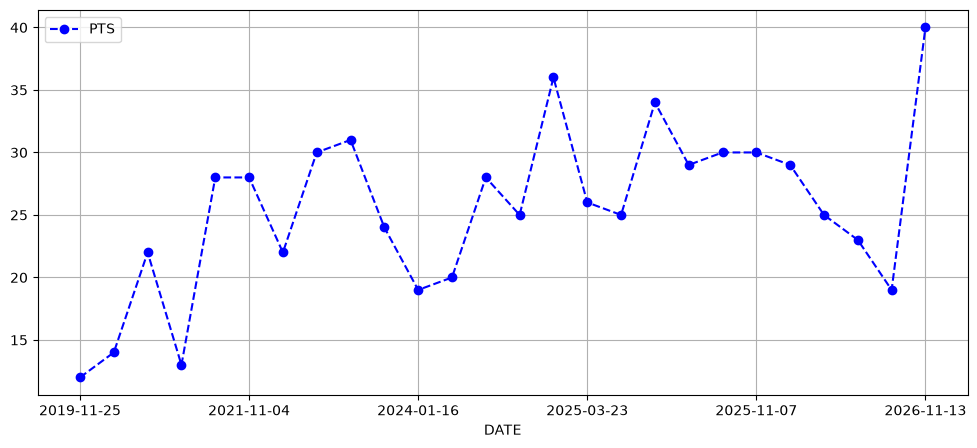

In [15]:
# MVPs
pname = 'Shai Gilgeous-Alexander'
#pname = 'Russell Westbrook'
#pname = 'LeBron James'
#pname = 'Nikola Jokic'
#pname = 'Kevin Durant'
#pname = 'James Harden'
#pname = 'Stephen Curry'
#pname = 'Joel Embiid'
#pname = 'Giannis Antetokounmpo'
# Misc
#pname = 'Luka Doncic'
#pname = 'Paul George'
#pname = 'Kawhi Leonard'
#pname = 'Jalen Williams'
#pname = 'Chet Holmgren'
#pname = 'Luguentz Dort'

print()
print(pname)
print()
playerLog = sl[sl['NAME']== pname].sort_values('DATE',ascending=True).drop(columns=['NAME']).set_index('DATE')
playerTotals = ballers[ballers['NAME']==pname].sort_values('PTS',ascending=False).set_index('NAME')
playerPerGame = playerTotals.drop(columns=['FG%']).div(len(playerLog)).round(2)
playerPerGame['FG%'] = round(100*playerPerGame['FGM']/playerPerGame['FGA'],1)
playerPerGame['3P%'] = round(100*playerPerGame['3PM']/playerPerGame['3PA'],1)
playerPerGame['FT%'] = round(100*playerPerGame['FTM']/playerPerGame['FTA'],1)

display(playerLog)
#playerTotals
#playerPerGame
playerLog.plot(y='PTS', marker='o',linestyle='--',color='blue',figsize=(12, 5))
plt.grid(True)


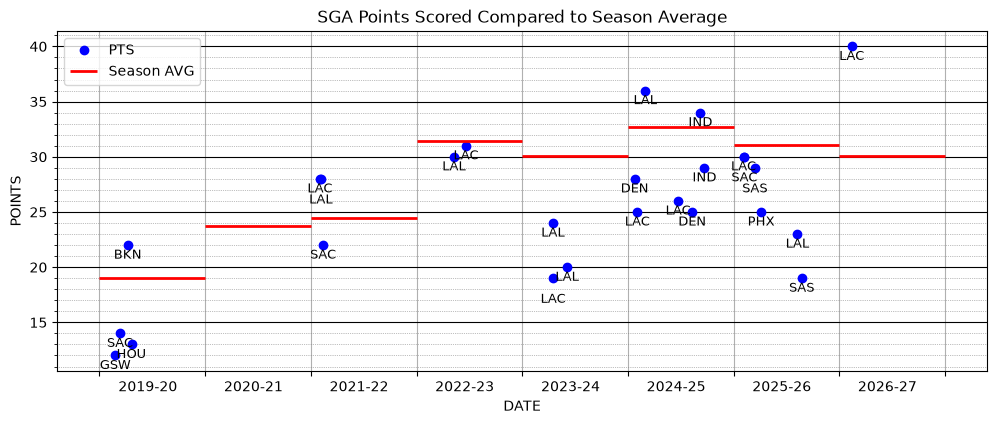

In [22]:
from matplotlib.ticker import MultipleLocator
shaiLog = sl[sl['NAME']== 'Shai Gilgeous-Alexander'].sort_values('DATE',ascending=True).drop(columns=['NAME']).set_index('DATE')
shaiLog.index = pd.to_datetime(shaiLog.index)
shaiLog.plot(y='PTS', marker='o',linestyle='None',color='blue',figsize=(12, 5))
plt.grid(True)
labels = ['   ','2019-20       ', '2020-21       ', '2021-22       ', '2022-23       ', '2023-24       ', '2024-25       ', '2025-26       ', '2026-27       ']
plt.xticks(['10/01/2019','10/01/2020','10/01/2021','10/01/2022','10/01/2023','10/01/2024','10/01/2025','10/01/2026','10/01/2027'],labels,rotation = 0)

seasons_data = [
    {"y": 19.0, "xmin": '10/01/2019', "xmax": '10/01/2020'},
    {"y": 23.7, "xmin": '10/01/2020', "xmax": '10/01/2021'},
    {"y": 24.5, "xmin": '10/01/2021', "xmax": '10/01/2022'},
    {"y": 31.4, "xmin": '10/01/2022', "xmax": '10/01/2023'},
    {"y": 30.1, "xmin": '10/01/2023', "xmax": '10/01/2024'},
    {"y": 32.7, "xmin": '10/01/2024', "xmax": '10/01/2025'},
    {"y": 31.1, "xmin": '10/01/2025', "xmax": '10/01/2026'},
    {"y": 30.1, "xmin": '10/01/2026', "xmax": '10/01/2027'}
]

for i, data in enumerate(seasons_data):
    lbl = 'Season AVG' if i == 0 else None
    plt.hlines(y=data["y"], xmin=data["xmin"], xmax=data["xmax"], 
               color='red', linestyle='-', linewidth=2, label=lbl)

prevDate = None
for date, row in shaiLog.iterrows():
    # plt.text(x, y, s) 
    # x = the date (index), y = the PTS value + a small offset so it doesn't touch the dot
    offset = 1.5
    if prevDate:
        if date - prevDate < pd.Timedelta(days=5):
            offset = 2.5
    if date == pd.Timestamp('2025-12-13'):
        offset = 2.5
    prevDate = date
    plt.text(date, row['PTS'] - offset, row['OPP'], fontsize=9, ha='center', va='bottom', rotation=0)
    
plt.gca().yaxis.set_minor_locator(MultipleLocator(1)) 
plt.gca().yaxis.set_major_locator(MultipleLocator(5))
plt.ylabel('POINTS')
plt.title('SGA Points Scored Compared to Season Average')
plt.grid(visible=True, which='major', axis='y', color='black', linestyle='-', linewidth=0.8)
plt.grid(visible=True, which='minor', axis='y', color='gray', linestyle=':', linewidth=0.5)
plt.legend(loc='upper left')
plt.show()

In [25]:
mvp_list = ['LeBron James','Derrick Rose','Kevin Durant','Stephen Curry','Russell Westbrook','James Harden',
        'Giannis Antetokounmpo','Nikola Jokic','Joel Embiid','Shai Gilgeous-Alexander'] # no D Rose :(
all_stars = ['Dwyane Wade','Paul George','Jamal Murray','Jalen Brunson','Anthony Davis','Bradley Beal',
             'Chris Paul','Damian Lillard','Devin Booker','Pascal Siakam', 'Carmelo Anthony','Dwight Howard',
             'Kawhi Leonard','DeMar DeRozan', 'Luka Doncic','Karl-Anthony Towns','Al Horford','Klay Thompson',
            'Draymond Green','John Wall','DeMarcus Cousins','Rajon Rondo','Domantas Sabonis','Ben Simmons',
            'Andre Drummond',"De'Aaron Fox",'Darius Garland','Tyrese Haliburton','Zach LaVine','Tyrese Maxey',
            'Victor Oladipo','Victor Wembanyama','Deni Avdija','LaMelo Ball','Paolo Banchero','Andre Iguodala',
            'DeAndre Jordan', 'Kyle Korver','Brook Lopez','Norman Powell',"D'Angelo Russell",'Roy Hibbert','Khris Middleton',
            'David West','Jarrett Allen','Andrew Wiggins','Alperen Sengun']
#plist = all_stars
plist = mvp_list
mvps = sl[sl['NAME'].isin(plist)].sort_values('DATE',ascending=True)
mvp_totals = mvps.groupby('NAME').sum(numeric_only=True).sort_values('G', ascending=False).reset_index().set_index('NAME')
mvp_totals['FG%'] = round(mvp_totals['FGM']/mvp_totals['FGA']*100,1)
display(mvp_totals)
display(mvps)

,MINS,PTS,REB,AST,STL,BLK,FGM,FGA,FG%,3PM,3PA,FTM,FTA,DREB,OREB,TO,PF,G
NAME,,,,,,,,,,,,,,,,,,
Shai Gilgeous-Alexander,921,662,112,154,39,27,226,507,44.6,37,124,173,192,95,17,71,69,26
Russell Westbrook,688,426,176,165,33,7,156,365,42.7,37,121,77,105,135,41,68,49,23
James Harden,357,217,69,88,9,14,61,160,38.1,29,88,66,75,60,9,36,31,10
LeBron James,211,143,43,41,7,0,57,107,53.3,10,25,19,24,42,1,24,9,6
Nikola Jokic,229,171,75,42,12,5,61,126,48.4,16,41,33,42,59,16,20,21,6
Kevin Durant,107,82,27,10,2,4,32,66,48.5,7,20,11,11,26,1,9,7,3
Giannis Antetokounmpo,58,41,22,11,1,5,13,27,48.1,0,4,15,23,17,5,11,5,2
Joel Embiid,51,57,13,3,6,1,20,28,71.4,5,9,12,16,13,0,4,5,2
Stephen Curry,30,21,9,6,3,0,8,19,42.1,5,12,0,0,8,1,2,2,1


,NAME,TEAM,DATE,OPP,MINS,PTS,REB,AST,STL,BLK,FGM,FGA,FG%,3PM,3PA,FTM,FTA,DREB,OREB,TO,PF,G
20,Russell Westbrook,OKC,2017-02-13,WAS,24,17,4,4,2,0,5,19,0.260,0,4,7,7,2,2,2,0,1
44,Giannis Antetokounmpo,MIL,2017-04-04,OKC,24,11,10,4,0,3,3,10,0.300,0,1,5,8,6,4,4,2,1
57,Russell Westbrook,OKC,2017-04-04,MIL,27,12,13,13,2,0,4,12,0.330,2,4,2,2,10,3,3,2,1
69,Russell Westbrook,OKC,2017-04-09,DEN,37,50,16,10,1,0,17,32,0.530,5,12,11,11,14,2,2,1,1
83,Nikola Jokic,DEN,2017-04-09,OKC,32,23,6,3,1,1,8,16,0.500,1,5,6,6,5,1,3,5,1
90,Russell Westbrook,OKC,2018-02-24,GSW,32,15,12,7,2,0,4,15,0.270,1,5,6,6,10,2,5,1,1
101,Kevin Durant,GSW,2018-02-24,OKC,32,28,5,2,1,1,10,20,0.500,4,6,4,4,5,0,2,0,1
103,Stephen Curry,GSW,2018-02-24,OKC,30,21,9,6,3,0,8,19,0.420,5,12,0,0,8,1,2,2,1
115,Russell Westbrook,OKC,2018-11-19,SAC,37,29,13,7,3,0,12,25,0.480,4,10,1,2,11,2,4,5,1
145,Kevin Durant,GSW,2018-11-21,OKC,35,27,14,3,0,3,11,22,0.500,1,5,4,4,13,1,6,2,1


In [26]:
sl.sort_values(by=['PTS'],ascending=False).head(32)
#sl.sort_values(by=['REB'],ascending=False).head(10)

,NAME,TEAM,DATE,OPP,MINS,PTS,REB,AST,STL,BLK,FGM,FGA,FG%,3PM,3PA,FTM,FTA,DREB,OREB,TO,PF,G
69,Russell Westbrook,OKC,2017-04-09,DEN,37,50,16,10,1,0,17,32,0.530,5,12,11,11,14,2,2,1,1
989,Luka Doncic,LAL,2026-11-02,MIA,36,42,7,13,2,0,14,24,0.583,6,15,8,10,7,0,2,2,1
583,Nikola Jokic,DEN,2024-10-26,LAC,37,41,9,4,2,1,14,26,0.540,7,12,6,8,6,3,5,2,1
1016,Shai Gilgeous-Alexander,OKC,2026-11-13,LAC,39,40,4,5,1,0,15,26,0.577,2,4,8,11,3,1,3,1,1
851,Jalen Brunson,NYK,2025-12-13,ORL,39,40,4,8,1,0,16,27,0.590,2,5,6,9,3,1,2,5,1
649,James Harden,LAC,2024-12-01,DEN,38,39,9,11,1,0,10,26,0.380,6,15,13,13,7,2,5,4,1
479,Paul George,LAC,2024-01-16,OKC,34,38,7,5,3,0,15,24,0.620,6,12,2,4,7,0,0,2,1
381,LeBron James,LAL,2023-02-07,OKC,34,38,7,3,3,0,13,20,0.650,4,6,8,10,7,0,4,3,1
593,Norman Powell,LAC,2024-10-26,DEN,33,37,3,0,1,0,14,21,0.670,7,11,2,3,2,1,0,1,1
638,Shai Gilgeous-Alexander,OKC,2024-11-29,LAL,37,36,6,9,2,1,13,28,0.460,3,10,7,8,3,3,3,3,1


In [20]:
ballers.sort_values(by=['G'],ascending=False).head(30)

,NAME,MINS,PTS,REB,AST,STL,BLK,FGM,FGA,FG%,3PM,3PA,FTM,FTA,DREB,OREB,TO,PF,G
353,Shai Gilgeous-Alexander,921,662,112,154,39,27,226,507,44.6,37,124,173,192,95,17,71,69,26
346,Russell Westbrook,688,426,176,165,33,7,156,365,42.7,37,121,77,105,135,41,68,49,23
255,Luguentz Dort,567,215,76,23,18,5,76,189,40.2,40,121,23,28,49,27,15,72,21
154,Isaiah Joe,355,161,59,14,12,3,57,142,40.1,40,109,7,9,43,16,9,20,19
230,Kenrich Williams,307,82,67,29,11,3,32,82,39.0,11,40,7,12,48,19,11,25,17
2,Aaron Wiggins,318,137,56,12,8,7,56,121,46.3,21,52,4,6,49,7,11,23,17
60,Cason Wallace,381,121,46,17,26,6,49,102,48.0,22,49,1,2,23,23,10,31,16
171,Jalen Williams,473,259,66,59,26,5,94,216,43.5,24,65,47,55,50,16,35,40,14
62,Chet Holmgren,415,192,121,28,7,26,73,147,49.7,9,47,37,51,98,23,24,35,14
11,Alex Caruso,306,94,41,33,17,4,34,85,40.0,15,51,11,15,30,11,6,35,13
